The 1D TISE is given as:
$$
-\frac{\hbar^2}{2m} \frac{d^2 \psi(x)}{dx^2} + V(x) \psi(x) = E \psi(x)
$$
The potential step is defined as:
$$
V(x) = 
\begin{cases} 
0, & x < 0 \\
V_{0}, & x \geq 0 
\end{cases}
$$

#### 1. IMPORTING NECESSARY PACKAGES

In [1]:
import numpy as np
import matplotlib.pyplot as plt

#### 2. *THE POTENTIAL STEP IS DEFINED AS ...*

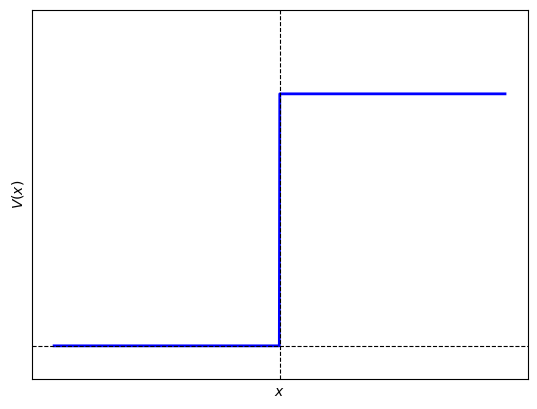

In [2]:
x = np.linspace(-3,3,1000)

V0 = 1.5
V = np.where(x<0,0,V0)

plt.plot(x,V,color="blue",linewidth=2)

plt.axhline(0,color="black",linestyle="--",linewidth=0.8)
plt.axvline(0,color="black",linestyle="--",linewidth=0.8)
plt.xlabel("$x$")
plt.ylabel("$V(x)$")
plt.xticks([])
plt.yticks([])
plt.ylim(-0.2,2)

plt.show()

#### 3. CASE $E>V_{0}$

In this case, the solutions to the TISE are given as:
$$
\psi(x) = 
\begin{cases} 
Ae^{ik_{1}x} + Be^{-ik_{1}x}, & x < 0 \\
Ce^{ik_{2}x}, & x \geq 0 
\end{cases}
$$
The boundary conditions yield:
$$
A + B = C \\
$$
$$
k_{1}(A-B) = k_{2}C
$$
We can solve these equations to find the required coefficients

##### (a) Defining the constants

In [3]:
hbar = 1
A = 1
m = 1

E = 3
V0 = 1.5
k1 = np.sqrt((2*m*E)/(hbar**2))
k2 = np.sqrt((2*m*(E-V0))/(hbar**2))

##### (b) Calculating the coefficients B/A, C/A and then R and T

In [4]:
B_A = (k1-k2)/(k1+k2)
C_A = (2*k1)/(k1+k2)

display(B_A,C_A)

np.float64(0.17157287525380988)

np.float64(1.1715728752538097)

In [5]:
R = np.abs(B_A)**2
T = (k2/k1)*np.abs(C_A)**2

display(R,T)

np.float64(0.029437251522859406)

np.float64(0.9705627484771403)

In [6]:
# Checking ...
print(f"R + T = {R+T}")

R + T = 0.9999999999999997


##### (c) Constructing and plotting the probability densities

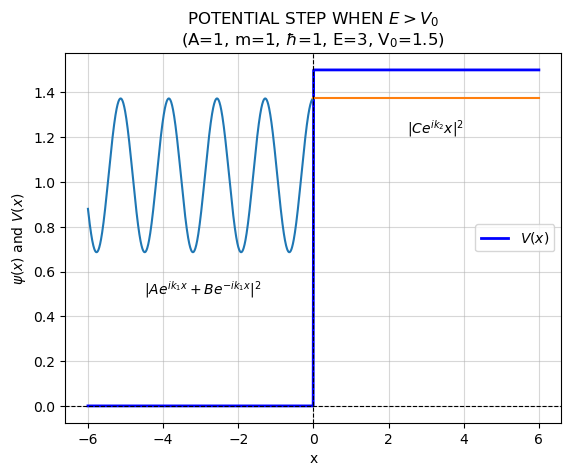

In [7]:
x = np.linspace(-6,6,1000)
x1 = np.linspace(-6,0,1000,endpoint=True)
x2 = np.linspace(0,6,1000,endpoint=True)

psi1 = A*np.exp(1j*k1*x1) + (B_A*A)*np.exp(-1j*k1*x1)
psi2 = (C_A*A)*np.exp(1j*k2*x2)

V = np.where(x<0,0,V0)

plt.plot(x,V,color='blue',linewidth=2,label="$V(x)$")
plt.plot(x1,np.abs(psi1)**2)
plt.plot(x2,np.abs(psi2)**2)

plt.title(r"POTENTIAL STEP WHEN $E>V_{0}$"+"\n"+r"(A=1, m=1, $\hbar$=1, E=3, V$_{0}$=1.5)")
plt.ylabel(r"$\psi(x)$ and $V(x)$")
plt.xlabel("x")
plt.axhline(0,color="black",linestyle="--",linewidth=0.8)
plt.axvline(0,color="black",linestyle="--",linewidth=0.8)
plt.text(-4.5,0.5,r"$|Ae^{ik_{1}x} + Be^{-ik_{1}x}|^{2}$")
plt.text(2.5,1.22,r"$|Ce^{ik_{2}}x|^{2}$")
plt.legend(loc=7)
plt.grid(alpha=0.5)

plt.show()

#### 4. CASE: $E<V_{0}$

In this case, the solutions to the TISE are given as:
$$
\psi(x) = 
\begin{cases} 
Ae^{ik_{1}x} + Be^{-ik_{1}x}, & x < 0 \\
Ce^{-k_{2}x}, & x \geq 0 
\end{cases}
$$
The boundary conditions yield:
$$
A + B = C
$$
$$
ik_{1}(A - B) = -k_{2}C
$$

##### (a) Defining the constants

In [8]:
hbar = 1
A = 1
m = 1

E = 4
V0 = 6
k1 = np.sqrt((2*m*E)/(hbar**2))
k2 = np.sqrt((2*m*(V0-E))/(hbar**2))

##### (b) Calculating the coefficients B/A, C/A and then R

In [9]:
B_A = (k1-1j*k2)/(k1+1j*k2)
C_A = (2*k1)/(k1+1j*k2)

display(B_A,C_A)

np.complex128(0.33333333333333337-0.9428090415820632j)

np.complex128(1.3333333333333333-0.9428090415820632j)

The transmission coefficient is defined as the ratio of the transmitted probability current density to the incident probability current density, and the probability current density is defined as: $J(x) = \frac{i\hbar}{2m}\left(\psi\frac{\partial \psi^{*}}{\partial x}-\psi^{*}\frac{\partial \psi}{\partial x}\right)$. Since, in this case the transmitted wave function is completely real, the $J_{\text{transmitted}}(x)$ vanishes, and thus $T = 0$.

In [10]:
R = np.abs(B_A)**2

print(f"R = {R} (T = 0)")

R = 0.9999999999999996 (T = 0)


##### (c) Constructing and plotting the probability densities

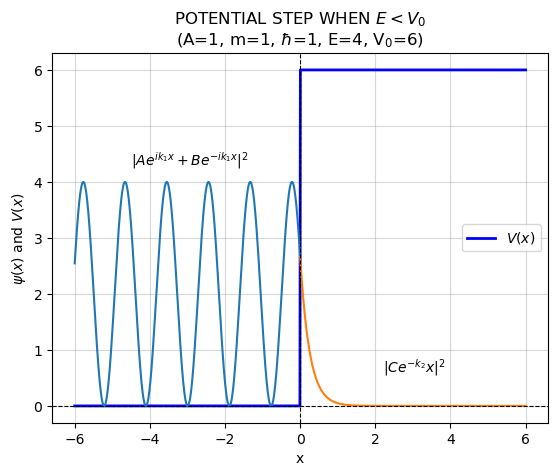

In [11]:
x = np.linspace(-6,6,1000)
x1 = np.linspace(-6,0,1000,endpoint=True)
x2 = np.linspace(0,6,1000,endpoint=True)

psi1 = A*np.exp(1j*k1*x1) + (B_A*A)*np.exp(-1j*k1*x1)
psi2 = (C_A*A)*np.exp(-k2*x2)

V = np.where(x<0,0,V0)

plt.plot(x,V,color='blue',linewidth=2,label="$V(x)$")
plt.plot(x1,np.abs(psi1)**2)
plt.plot(x2,np.abs(psi2)**2)

plt.title(r"POTENTIAL STEP WHEN $E<V_{0}$"+"\n"+r"(A=1, m=1, $\hbar$=1, E=4, V$_{0}$=6)")
plt.ylabel(r"$\psi(x)$ and $V(x)$")
plt.xlabel("x")
plt.axhline(0,color="black",linestyle="--",linewidth=0.8)
plt.axvline(0,color="black",linestyle="--",linewidth=0.8)
plt.text(-4.5,4.3,r"$|Ae^{ik_{1}x} + Be^{-ik_{1}x}|^{2}$")
plt.text(2.2,0.6,r"$|Ce^{-k_{2}}x|^{2}$")
plt.legend(loc=7)
plt.grid(alpha=0.5)

plt.show()